# 01 — Exploratory Data Analysis: `quentin_house`

**Goal of the project.** Learn a mapping from an 8-hour transient — indoor air temperature
$T_{int}(t)$ and injected heating power $U(t)$ — to six intrinsic thermal indicators of the
building:

| Family | Targets | Unit | Physical meaning |
|---|---|---|---|
| HLC | $HLC$ | W/K | steady-state heat loss per kelvin of indoor–boundary difference |
| Hb | $HLC_{mit}$, $HLC_{ext}$ | W/K | split of the HLC towards adjoining spaces / outdoors ($HLC = HLC_{mit} + HLC_{ext}$) |
| CDT | $\tau_b$, $\tau_n$, $\tau_\infty$ | h | time constants: structural discharge, 8 h night-cooling persistence, mean residence time |

**Goal of this notebook.** Understand the data *before* any deep learning:

1. Check the data contract (shapes, units, sampling, label order, integrity).
2. Describe the targets statistically and the physical structure linking them.
3. Describe the excitation design and verify it is independent of the targets.
4. Look at the time series and isolate the effect of the building from the effect of the excitation.
5. Summarise the patterns found and what they imply for the model design.

> **Physical reminder.** The building is a linear network of thermal capacities and conductances:
> $C\,\dot{T} = A\,T + E\,u$. The HLC is the inverse of the steady-state gain from heating power to
> indoor temperature, $HLC = 1/[S]_{11}$ with $S = G - J A^{-1} E$. Reaching that steady state takes
> several $\tau_b$ (days), while we only observe 8 h: the HLC must be *inferred* from the transient.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from ipe_prediction.data import DT_HOURS, TARGET_NAMES, TARGET_UNITS, batch_files
from ipe_prediction.util_assessement import load_single_batch
from ipe_prediction.eda import descriptors as E, plotting as P
from ipe_prediction.eda.loading import load_dataset, load_targets_only

P.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
torch.manual_seed(0)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = ROOT / "quentin_house"
FIGS = ROOT / "outputs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIGS / f"{name}.png", dpi=130, bbox_inches="tight")


print(f"data folder: {DATA}  ({len(batch_files(DATA))} batch files)")

data folder: C:\Users\ayman\Projects\IPE_prediction\quentin_house  (20 batch files)


## 1. Data contract and integrity

We first open one raw batch to see exactly what the simulator stored, then load two batches
(100 000 simulations) for all time-series analyses. Targets alone are tiny, so section 2 scans
**all 1 000 000** simulations.

In [2]:
raw = load_single_batch(batch_files(DATA)[0])
fields = {k: getattr(raw, k) for k in ["indoor_temperature", "indoor_U", "HLC", "Hb", "CDT", "solicitation"]}
display(pd.DataFrame({k: {"shape": tuple(v.shape), "dtype": str(v.dtype)} for k, v in fields.items()}).T)
print("Hb_labels               :", raw.Hb_labels, " <- column 0 is HLC_mit, column 1 is HLC_ext")
print("solicitation_field_names:", raw.solicitation_field_names)
del raw, fields

,shape,dtype
indoor_temperature,"(50000, 480)",torch.float32
indoor_U,"(50000, 480)",torch.float32
HLC,"(50000,)",torch.float32
Hb,"(50000, 2)",torch.float32
CDT,"(50000, 3)",torch.float32
solicitation,"(50000, 12)",torch.float32


Hb_labels               : ['HLC_mit', 'HLC_ext']  <- column 0 is HLC_mit, column 1 is HLC_ext
solicitation_field_names: ['max_power_wat', 'start_amplitude_wat', 'end_amplitude_wat', 'start_period_hours', 'end_period_hours', 'transition_speed', 'phase_shift', 'average_fluctuation_wat', 'prbs_min_duration_hours', 'prbs_max_duration_hours', 'prbs_probability_on', 'prbs_seed']


**Label order trap.** `Hb_labels = ['HLC_mit', 'HLC_ext']`: the first column is the *adjoining-space*
part. Everything downstream uses the canonical order `HLC, HLC_mit, HLC_ext, tau_b, tau_n, tau_inf`
(see `ipe_prediction.data.TARGET_NAMES`).

The excitation parameters (`solicitation`) are **not** model inputs (in the field the model only sees
the measured $U(t)$), but they are very useful to analyse what makes a test informative.

In [3]:
t0 = time.time()
ds = load_dataset(DATA, batch_indices=[1, 2], quantize=True)   # rounding as in the assessment
print(f"loaded {ds.n_sims:,} simulations x {ds.n_steps} steps in {time.time() - t0:.1f}s")

T, U, Y = ds.temperature, ds.power, ds.targets
dT_step = T.diff(dim=1)
checks = {
    "NaN / inf in T, U, Y": int((~torch.isfinite(T)).sum() + (~torch.isfinite(U)).sum() + (~torch.isfinite(Y)).sum()),
    "duration [h]": ds.n_steps * DT_HOURS,
    "T range [degC]": (round(T.min().item(), 2), round(T.max().item(), 2)),
    "distinct T(0) values": T[:, 0].unique().tolist(),
    "distinct U values [W]": U.unique().tolist(),
    "duplicated target rows": int(ds.n_sims - torch.unique(Y, dim=0).shape[0]),
    "median |dT| per minute [K]": round(dT_step.abs().median().item(), 4),
    "share of minutes with dT == 0 after rounding": round((dT_step == 0).float().mean().item(), 3),
}
pd.Series(checks, name="value").to_frame()

loaded 100,000 simulations x 480 steps in 0.4s


,value
"NaN / inf in T, U, Y",0
duration [h],8.0
T range [degC],"(24.36, 49.54)"
distinct T(0) values,[24.62]
distinct U values [W],"[0.0, 7000.0]"
duplicated target rows,0
median |dT| per minute [K],0.02
share of minutes with dT == 0 after rounding,0.207


**Reading.**

* Every series is **480 samples at 1 min = 8 h**, with no missing values.
* **Every simulation starts from the same air temperature** $T_{int}(0)$: the
  simulator only randomised the *hidden* initial state (wall nodes), not the air. The meaningful signal is
  therefore $\Delta T(t) = T_{int}(t) - T_{int}(0)$.
* $U(t)$ is **binary**: the heater is either off or at full power (7 kW).
* The 0.01 °C rounding is of the same order as the per-minute increments: the derivative $dT/dt$ is
  noisy at 1-minute resolution, and slopes must be estimated over several minutes.

## 2. Targets — distribution and physical structure (1 000 000 simulations)

In [4]:
t0 = time.time()
tg = load_targets_only(DATA)
Yall = tg.targets
print(f"scanned {tg.n_sims:,} simulations in {time.time() - t0:.1f}s")

desc = pd.DataFrame(Yall.numpy(), columns=TARGET_NAMES).describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc["CV_%"] = 100 * desc["std"] / desc["mean"]
desc["skew"] = pd.DataFrame(Yall.numpy(), columns=TARGET_NAMES).skew()
desc["unit"] = [TARGET_UNITS[n] for n in TARGET_NAMES]
desc

scanned 1,000,000 simulations in 2.9s


,count,mean,std,min,1%,25%,50%,75%,99%,max,CV_%,skew,unit
HLC,1000000.0,232.926,31.329,111.403,166.464,210.645,231.800,254.131,307.908,367.995,13.450,0.179,W/K
HLC_mit,1000000.0,120.488,26.256,42.843,69.368,100.862,118.900,138.552,183.462,231.533,21.791,0.282,W/K
HLC_ext,1000000.0,112.438,17.112,52.646,75.650,100.266,112.188,124.264,152.246,185.892,15.219,0.101,W/K
tau_b,1000000.0,50.001,10.097,20.199,31.530,42.785,48.819,55.946,78.765,122.885,20.193,0.713,h
tau_n,1000000.0,11.039,2.009,5.172,7.404,9.605,10.791,12.204,16.831,25.839,18.198,0.753,h
tau_inf,1000000.0,31.231,7.530,10.485,18.083,25.825,30.199,35.518,53.383,93.119,24.110,0.849,h


In [5]:
hlc, mit, ext, tb, tn, tinf = Yall.T
physics_checks = {
    "max |HLC - (HLC_mit + HLC_ext)| [W/K]": (hlc - mit - ext).abs().max().item(),
    "all targets > 0": bool((Yall > 0).all()),
    "share tau_n <= tau_inf": (tn <= tinf).float().mean().item(),
    "share tau_inf <= tau_b": (tinf <= tb).float().mean().item(),
    "share HLC_ext > HLC_mit": (ext > mit).float().mean().item(),
}
pd.Series(physics_checks, name="value").to_frame()

,value
max |HLC - (HLC_mit + HLC_ext)| [W/K],0.0
all targets > 0,True
share tau_n <= tau_inf,1.0
share tau_inf <= tau_b,1.0
share HLC_ext > HLC_mit,0.413


**Hard physical structure, confirmed on 1M simulations.**

* $HLC = HLC_{mit} + HLC_{ext}$ holds to float precision. This is an **exact** constraint, so it should
  be built into the model (predict both parts with positive activations and sum them) rather than learned.
* $\tau_n \le \tau_\infty \le \tau_b$ holds **in every simulation**. This matches the physics: $\tau_\infty$ is a
  weighted average of the building's modal time constants (so it cannot exceed the slowest one,
  linked to $\tau_b$), and $\tau_n$ is the same average after only 8 h of loading, before the slow modes are charged.
  An ordered parameterisation (e.g. $\tau_\infty = \tau_n + \mathrm{softplus}(\cdot)$) makes it hold by construction.

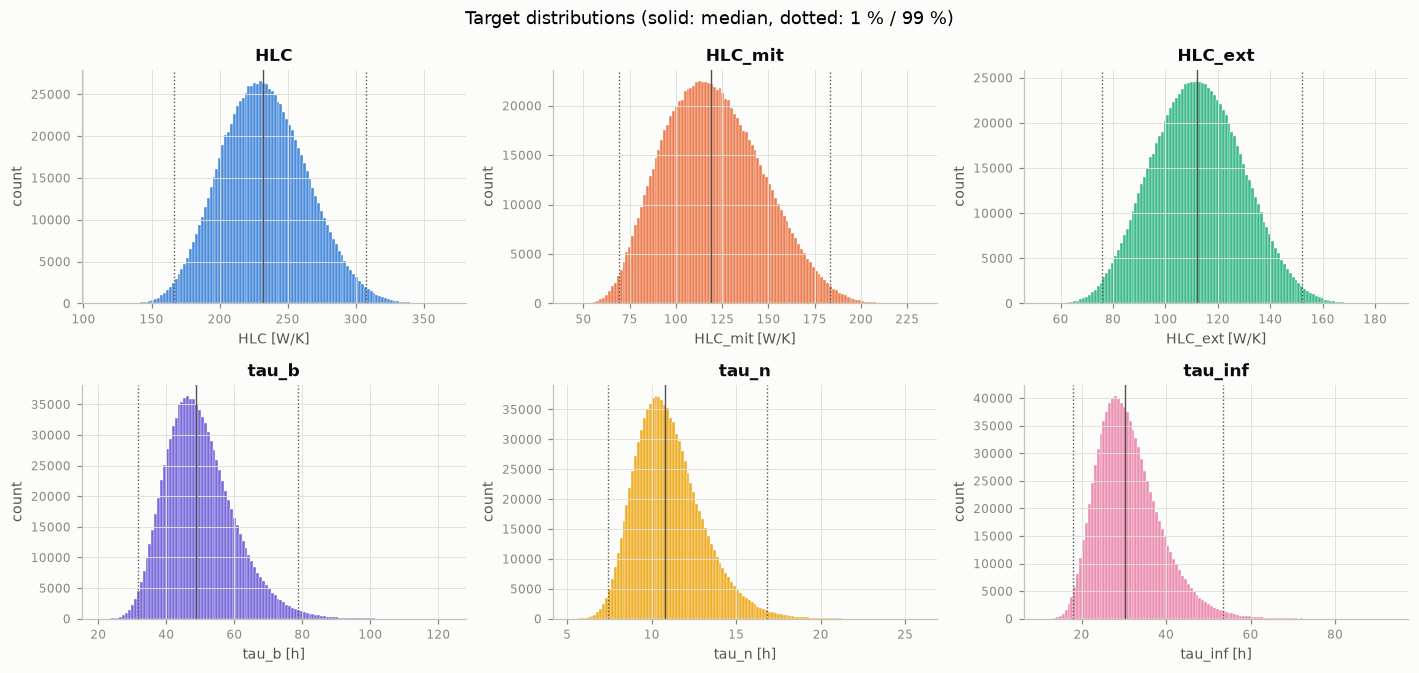

In [6]:
fig = P.target_histograms(Yall)
save(fig, "02_target_histograms")

The targets are unimodal and mildly right-skewed (the time constants most of all, with long upper tails).
This is what Monte Carlo sampling of thermophysical parameters within ±x % of nominal values gives
(paper §2.1.1). A **log transform** of the targets is natural: it makes the tails symmetric, matches the
multiplicative nature of the parameters, and turns relative errors into absolute ones.

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
HLC,1.000000,0.830000,0.530000,-0.680000,-0.550000,-0.610000
HLC_mit,0.830000,1.000000,0.000000,-0.560000,-0.440000,-0.500000
HLC_ext,0.530000,0.000000,1.000000,-0.380000,-0.340000,-0.360000
tau_b,-0.680000,-0.560000,-0.380000,1.000000,0.750000,0.960000
tau_n,-0.550000,-0.440000,-0.340000,0.750000,1.000000,0.820000
tau_inf,-0.610000,-0.500000,-0.360000,0.960000,0.820000,1.000000


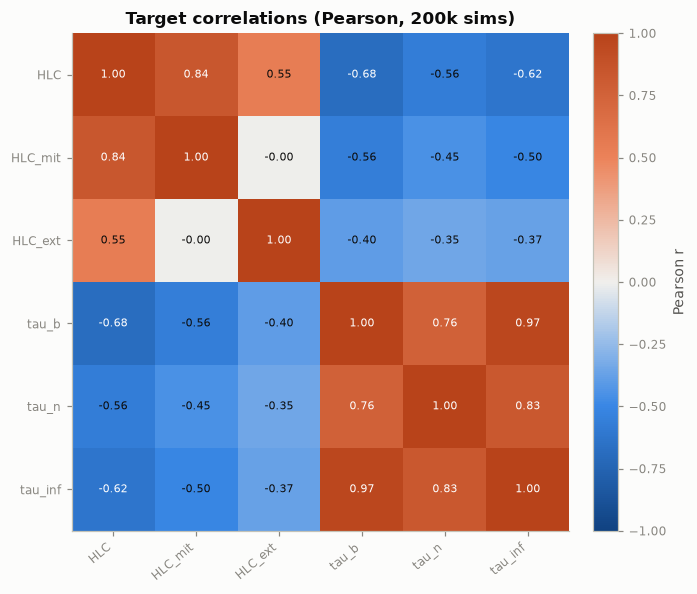

In [7]:
sub = pd.DataFrame(Yall[:200_000].numpy(), columns=TARGET_NAMES)
fig = P.correlation_heatmap(sub.corr(method="pearson"), "Target correlations (Pearson, 200k sims)")
save(fig, "02_target_corr")
display(sub.corr(method="spearman").round(2).style.set_caption("Spearman rank correlation"))

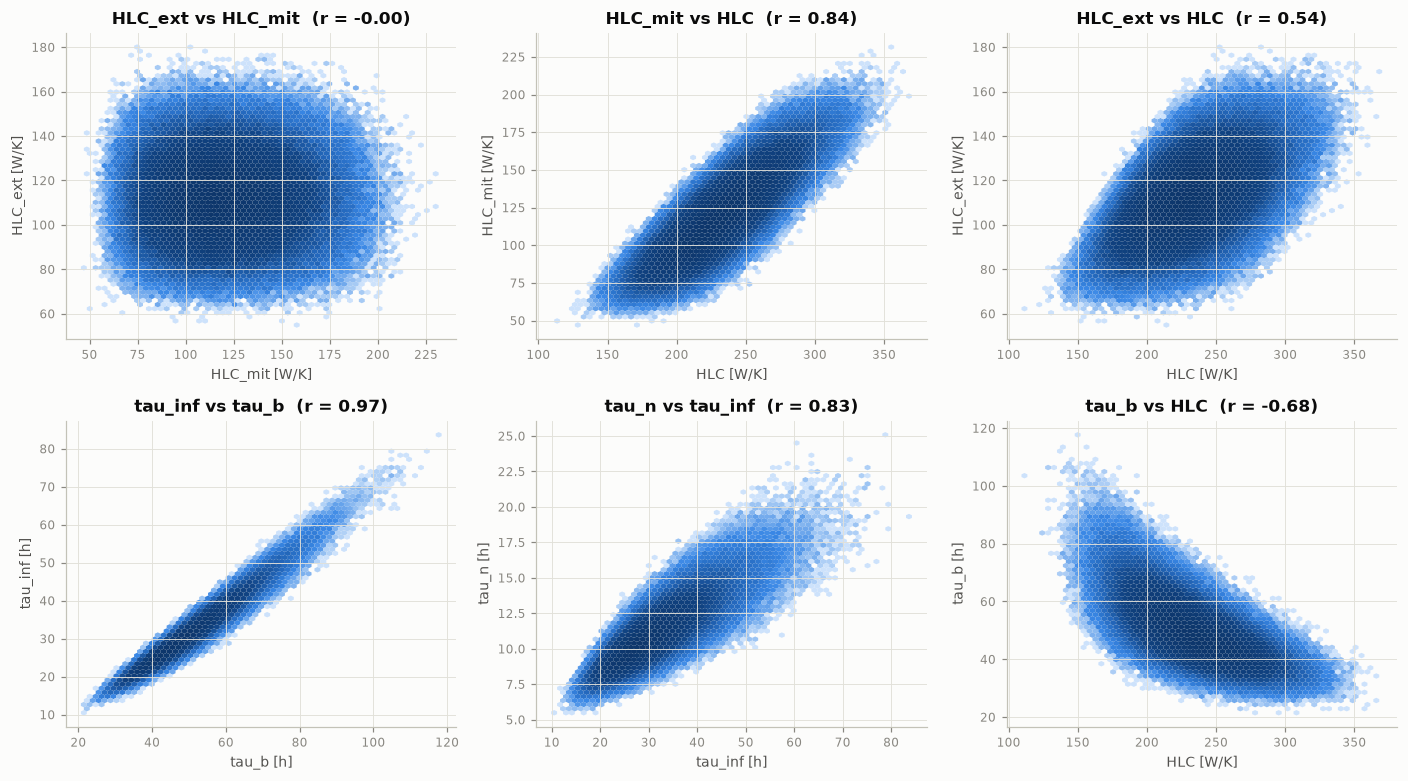

In [8]:
pairs = [("HLC_mit", "HLC_ext"), ("HLC", "HLC_mit"), ("HLC", "HLC_ext"),
         ("tau_b", "tau_inf"), ("tau_inf", "tau_n"), ("HLC", "tau_b")]
fig = P.hexbin_pairs(Yall[:300_000], pairs)
save(fig, "02_target_pairs")

**What the correlations say.**

* $HLC_{mit} \perp HLC_{ext}$ (r ≈ 0): the two loss paths were sampled independently. The split cannot
  be inferred from the population prior. Any skill on it must come from the signal itself.
* $HLC$ is dominated by $HLC_{mit}$ (r ≈ 0.84), which is also the more variable part.
* The three time constants form a tight block ($\tau_b$–$\tau_\infty$ r ≈ 0.97). They mostly share one
  underlying "inertia" factor. A multi-task model can exploit this redundancy.
* Time constants are **negatively** correlated with the HLC: $\tau \sim C / H$, so for similar
  capacities a leakier building responds faster.

C_b quantiles 1/50/99 % [MJ/K]: [28.9 40.9 55.8]


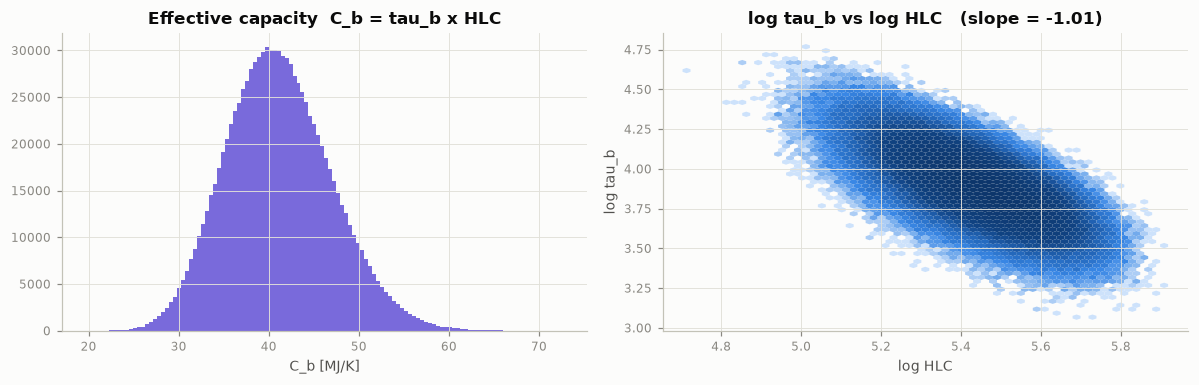

In [9]:
cap_b = (tb * 3600 * hlc / 1e6)               # MJ/K, "effective capacity" implied by tau_b
log_h, log_tb = np.log(hlc.double().numpy()), np.log(tb.double().numpy())
slope = np.polyfit(log_h[:200_000], log_tb[:200_000], 1)[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(cap_b.numpy(), bins=120, color=P.SERIES[6], alpha=0.85)
axes[0].set_title("Effective capacity  C_b = tau_b x HLC")
axes[0].set_xlabel("C_b [MJ/K]")
axes[1].hexbin(log_h[:300_000], log_tb[:300_000], gridsize=60, cmap=P.SEQUENTIAL, bins="log", mincnt=1, lw=0)
axes[1].set_title(f"log tau_b vs log HLC   (slope = {slope:.2f})")
axes[1].set_xlabel("log HLC"); axes[1].set_ylabel("log tau_b")
fig.tight_layout(); save(fig, "02_capacity")
print("C_b quantiles 1/50/99 % [MJ/K]:", np.quantile(cap_b.numpy(), [0.01, 0.5, 0.99]).round(1))

For a single-capacity building $\tau = C/HLC$, so $\log\tau$ vs $\log HLC$ would have slope −1 at fixed
$C$. The observed slope is much flatter and $C_b=\tau_b\cdot HLC$ spans a wide range, so **capacity and
losses vary partly independently**. Inertia carries information that the HLC does not contain, and the
reverse is also true.

In [10]:
per_batch = pd.DataFrame(Yall.numpy(), columns=TARGET_NAMES).groupby(tg.batch_id.numpy()).mean()
global_mean, global_std = Yall.mean(0).numpy(), Yall.std(0).numpy()
z = (per_batch - global_mean) / (global_std / np.sqrt(50_000))       # z-score of each batch mean
print("max |z| of batch means across 20 batches:", np.abs(z.to_numpy()).max().round(2))
per_batch.round(2)

max |z| of batch means across 20 batches: 2.44


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
1,233.08,120.53,112.54,49.96,11.04,31.21
2,232.72,120.26,112.46,50.07,11.05,31.27
3,232.81,120.34,112.46,49.98,11.04,31.22
4,232.87,120.47,112.40,50.00,11.03,31.23
5,233.14,120.69,112.46,49.94,11.03,31.20
6,232.80,120.50,112.30,50.04,11.04,31.25
7,232.91,120.49,112.42,49.97,11.03,31.21
8,232.92,120.43,112.49,49.99,11.03,31.21
9,233.02,120.53,112.49,49.96,11.03,31.20
10,232.88,120.35,112.54,50.04,11.06,31.27


Batch means agree to within sampling noise: the 20 files are i.i.d. draws from the same population.
**A random split (or a split by batch file) is legitimate.** Splitting by batch is the cleaner option,
since it keeps whole files out of training.

## 3. The excitation $U(t)$

Each simulation stores two views of the heating applied to the zone:

* **`indoor_U`**, the realised heating power, sampled at every one of the 480 minutes. This is the
  *dish*: what was actually injected, and what a power meter records on site.
* **`solicitation`**, the 12 settings of the signal generator that produced it (`solicitation_field_names`).
  This is the *recipe*. The generator is the one described in the paper's annex and can produce
  either a smooth **sine wave** or a random on/off **Pseudo-Random Binary Sequence (PRBS)**.

> **Model inputs vs analysis variables.** The model receives $U(t)$ at all 480 steps, as the assessment
> states ($X = \{T_{int}(t), U(t)\}$), because on a real building the injected power is measured
> (paper §2.2.1, 1-minute logging). The generator settings are **never** given to the model: in the
> field nobody knows the recipe, only the measured signal. They remain very useful to *analyse* the data
> and, later, the errors.

In [11]:
ex = pd.DataFrame(tg.excitation.numpy(), columns=tg.excitation_names)
group = {n: "shared" for n in ["max_power_wat"]}
group |= {n: "sine wave" for n in ["start_amplitude_wat", "end_amplitude_wat", "start_period_hours",
                                   "end_period_hours", "transition_speed", "phase_shift",
                                   "average_fluctuation_wat"]}
group |= {n: "PRBS" for n in ["prbs_min_duration_hours", "prbs_max_duration_hours",
                              "prbs_probability_on", "prbs_seed"]}
ex_summary = pd.DataFrame({"generator": pd.Series(group), "n_unique": ex.nunique(),
                           "min": ex.min(), "max": ex.max()}).loc[tg.excitation_names]
ex_summary

,generator,n_unique,min,max
max_power_wat,shared,1,7.000e+03,7000.0
start_amplitude_wat,sine wave,1,0.000e+00,0.0
end_amplitude_wat,sine wave,1,0.000e+00,0.0
start_period_hours,sine wave,1,0.000e+00,0.0
end_period_hours,sine wave,1,0.000e+00,0.0
transition_speed,sine wave,1,1.400e+01,14.0
phase_shift,sine wave,1,0.000e+00,0.0
average_fluctuation_wat,sine wave,1,0.000e+00,0.0
prbs_min_duration_hours,PRBS,980744,3.895e-06,2.0
prbs_max_duration_hours,PRBS,980744,7.789e-06,4.0


**Reading the 12 settings (all 1 000 000 simulations).**

| Group | Setting | Value in the data | Meaning |
|---|---|---|---|
| shared | `max_power_wat` | 7000 (constant) | heater capacity, the "on" level of the PRBS, hence $U \in \{0, 7000\}$ W |
| sine wave | `start_/end_amplitude_wat` | 0 (constant) | sine amplitude at the start / end of the test |
| sine wave | `start_/end_period_hours` | 0 (constant) | sine period at the start / end of the test |
| sine wave | `transition_speed` | 14 (constant) | speed of the sigmoid blend from the start regime to the end regime, centred at mid-test |
| sine wave | `phase_shift` | 0 (constant) | phase of the sine |
| sine wave | `average_fluctuation_wat` | 0 (constant) | not described in the paper; most likely a mean offset of the sine |
| PRBS | `prbs_min_duration_hours` $t_{min}$ | ≈ 0 → 2 h | shortest block |
| PRBS | `prbs_max_duration_hours` $t_{max}$ | exactly $2\,t_{min}$ | longest block (the paper's assumption $t_{max}=2\,t_{min}$) |
| PRBS | `prbs_probability_on` $p_{on}$ | 0.2 → 0.9 | probability that a block is "on" |
| PRBS | `prbs_seed` | 42 (constant) | random seed. It is the same everywhere while the patterns all differ, so it does not drive the per-simulation randomness |

**The sine-wave settings are all constant (amplitudes and periods are 0), so they are unused: no
simulation has a sinusoidal excitation.** They are leftovers from the generator's file format
(`transition_speed = 14` is a default with no effect). The only active generator is the **PRBS**, with
**two free settings**: $t_{min}$ and $p_{on}$.

**How the PRBS builds $U(t)$** (paper annex). The 8 h window is cut into consecutive blocks whose
durations are drawn uniformly in $[t_{min}, 2\,t_{min}]$ (mean $1.5\,t_{min}$). Each block is independently
at $P_{max} = 7$ kW with probability $p_{on}$, otherwise 0:

$$U(t) = \sum_k P_k\,\mathbb{1}_{[t_k, t_{k+1})}(t), \qquad P_k = \begin{cases} 7000 \text{ W} & \text{w.p. } p_{on} \\ 0 & \text{w.p. } 1-p_{on}\end{cases}$$

Two consequences follow, checked below:

1. $p_{on}$ sets **how much** heat is injected: $\mathbb{E}[\text{duty cycle}] = p_{on}$.
2. $t_{min}$ sets **how fast** the heater switches: there are about $8 / (1.5\,t_{min})$ blocks, and two
   consecutive blocks differ with probability $2\,p_{on}(1-p_{on})$. So
   $\mathbb{E}[\text{switches}] \approx \dfrac{8}{1.5\,t_{min}} \cdot 2\,p_{on}(1-p_{on})$, capped at 479 for sub-minute blocks.

In [12]:
desc_u = E.excitation_descriptors(U)
duty, nsw = desc_u["duty_cycle"], desc_u["n_switches"]
all_off, always_on = (U.amax(1) == 0), (U.amin(1) > 0)
tmin = ds.excitation[:, ds.excitation_names.index("prbs_min_duration_hours")]
tmax = ds.excitation[:, ds.excitation_names.index("prbs_max_duration_hours")]
p_on = ds.excitation[:, ds.excitation_names.index("prbs_probability_on")]
expected_sw = (8.0 / (1.5 * tmin)).clamp(max=ds.n_steps - 1) * 2 * p_on * (1 - p_on)

checks_u = {
    "t_max / t_min (min, max)": (round((tmax / tmin).min().item(), 4), round((tmax / tmin).max().item(), 4)),
    "corr(duty cycle, p_on)": round(np.corrcoef(duty.numpy(), p_on.numpy())[0, 1], 3),
    "corr(log(1+switches), log(1+expected switches))":
        round(np.corrcoef(np.log1p(nsw.numpy()), np.log1p(expected_sw.numpy()))[0, 1], 3),
    "share with t_min < 1 min (switches almost every step)": round((tmin < 1 / 60).float().mean().item(), 4),
    "heater never on": f"{all_off.float().mean().item():.1%}",
    "heater always on": f"{always_on.float().mean().item():.1%}",
}
display(pd.Series(checks_u, name="value").to_frame())

regimes_u = {"never on": all_off, "always on": always_on, "all simulations": torch.ones_like(all_off)}
pd.DataFrame({name: {"n": int(m.sum()), "median t_min [h]": tmin[m].median().item(),
                     "median p_on": p_on[m].median().item()} for name, m in regimes_u.items()}).T.round(2)

,value
"t_max / t_min (min, max)","(2.0, 2.0)"
"corr(duty cycle, p_on)",0.761
"corr(log(1+switches), log(1+expected switches))",0.921
share with t_min < 1 min (switches almost every step),0.008
heater never on,8.4%
heater always on,0.9%


,n,median t_min [h],median p_on
never on,8382.0,1.47,0.24
always on,857.0,1.65,0.89
all simulations,100000.0,1.00,0.55


* $t_{max} = 2\,t_{min}$ exactly, as in the paper's annex.
* The duty cycle follows $p_{on}$ (r ≈ 0.76) but not perfectly. With long blocks there are only a few
  draws in 8 h, so chance dominates.
* The switch-count formula matches the data well (r ≈ 0.92 in log scale): **$t_{min}$ is the switching-speed knob**.
* The two special groups are explained by the recipe. **Never on** happens with long blocks and a low
  $p_{on}$: 2–3 blocks that are each off about 75 % of the time are often all off. **Always on** happens with long
  blocks and a high $p_{on}$.

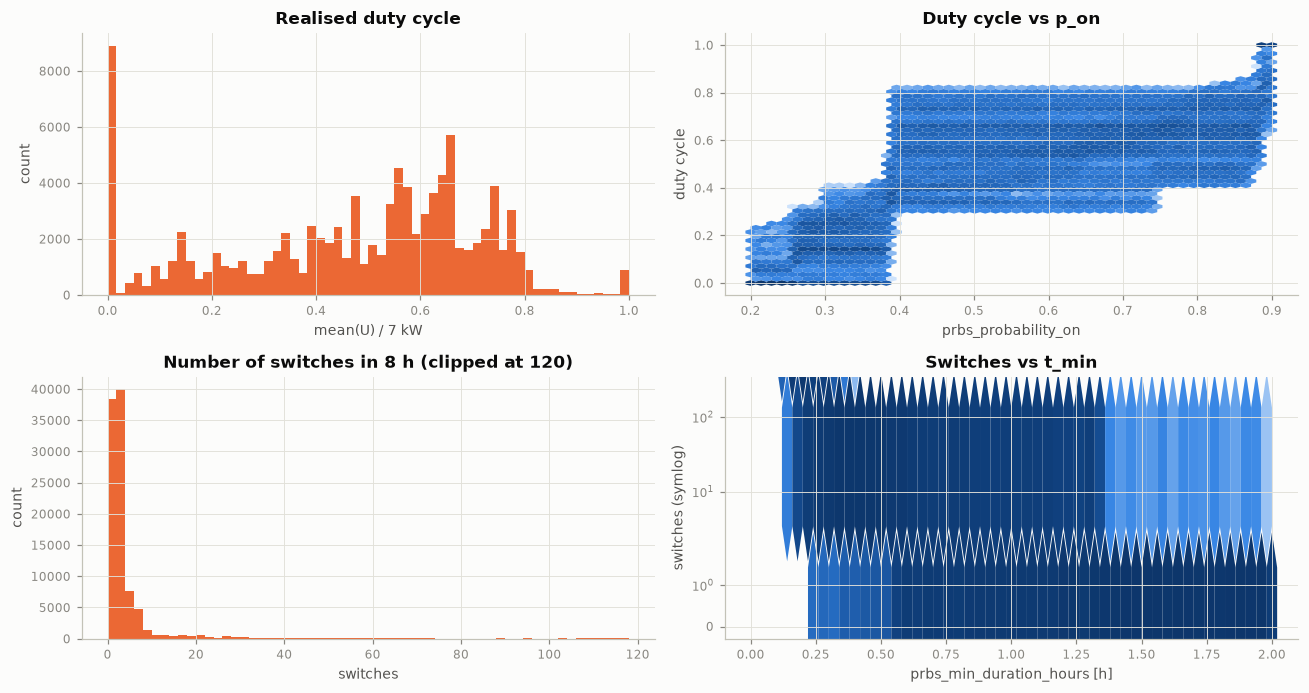

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4))
axes[0, 0].hist(duty.numpy(), bins=60, color=P.SERIES[1])
axes[0, 0].set_title("Realised duty cycle"); axes[0, 0].set_xlabel("mean(U) / 7 kW"); axes[0, 0].set_ylabel("count")
axes[0, 1].hexbin(p_on.numpy(), duty.numpy(), gridsize=50, cmap=P.SEQUENTIAL, bins="log", mincnt=1, lw=0)
axes[0, 1].set_title("Duty cycle vs p_on"); axes[0, 1].set_xlabel("prbs_probability_on"); axes[0, 1].set_ylabel("duty cycle")
axes[1, 0].hist(nsw.numpy(), bins=np.arange(0, 120, 2), color=P.SERIES[1])
axes[1, 0].set_title("Number of switches in 8 h (clipped at 120)"); axes[1, 0].set_xlabel("switches"); axes[1, 0].set_ylabel("count")
axes[1, 1].hexbin(tmin.numpy(), nsw.numpy(), gridsize=50, cmap=P.SEQUENTIAL, bins="log", mincnt=1, lw=0)
axes[1, 1].set_yscale("symlog"); axes[1, 1].set_title("Switches vs t_min")
axes[1, 1].set_xlabel("prbs_min_duration_hours [h]"); axes[1, 1].set_ylabel("switches (symlog)")
fig.tight_layout(); save(fig, "03_excitation")

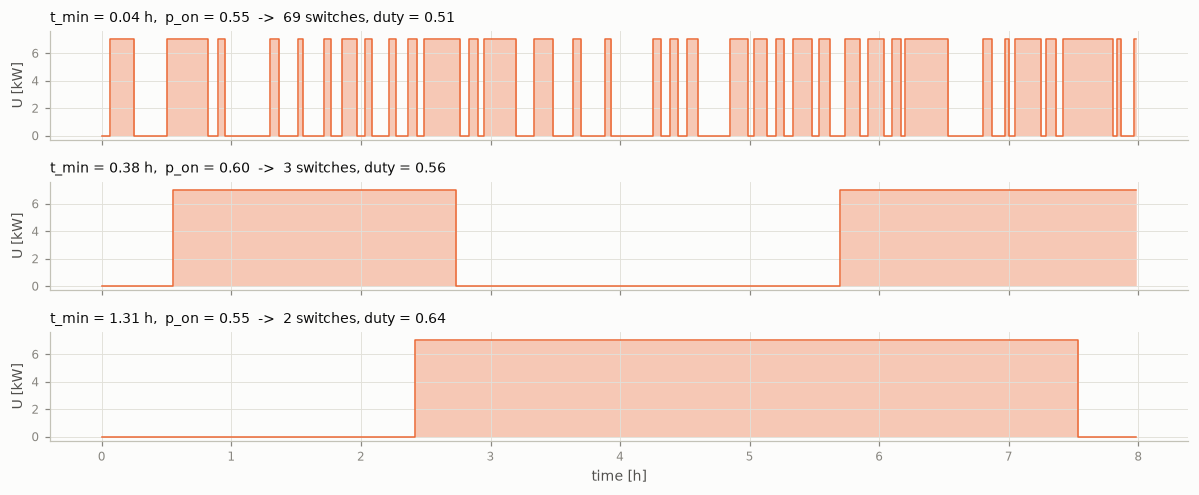

In [14]:
# Three recipes, three very different signals: fast, medium and slow switching
examples = []
for lo, hi in [(0.0, 0.05), (0.2, 0.4), (1.2, 1.6)]:
    m = (tmin >= lo) & (tmin < hi) & (~all_off) & (~always_on) & (p_on > 0.4) & (p_on < 0.6)
    examples.append(int(torch.nonzero(m)[0]))
fig, axes = plt.subplots(3, 1, figsize=(11, 4.6), sharex=True)
for ax, i in zip(axes, examples):
    ax.fill_between(ds.time_hours.numpy(), U[i].numpy() / 1000, step="post", color=P.SERIES[1], alpha=0.35, lw=0)
    ax.step(ds.time_hours.numpy(), U[i].numpy() / 1000, where="post", color=P.SERIES[1], lw=1)
    ax.set_ylabel("U [kW]"); ax.set_ylim(-0.3, 7.6)
    ax.set_title(f"t_min = {tmin[i]:.2f} h,  p_on = {p_on[i]:.2f}  ->  {int(nsw[i])} switches, duty = {duty[i]:.2f}",
                 fontsize=9, fontweight="normal", loc="left")
axes[-1].set_xlabel("time [h]")
fig.tight_layout(); save(fig, "03_prbs_examples")

In [15]:
cols = ["prbs_min_duration_hours", "prbs_probability_on"]
leak = pd.concat([ex[cols][:200_000], sub], axis=1).corr().loc[cols, TARGET_NAMES]
display(leak.round(4).style.set_caption("Correlation excitation settings x targets"))

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
prbs_min_duration_hours,-0.001800,-0.002600,0.000700,-0.001000,-0.000100,-0.000700
prbs_probability_on,0.002800,0.002600,0.001200,-0.002100,-0.000200,-0.001800


**The heating is not related to the building.** The two active settings are uncorrelated with every
target (|r| < 0.01): the heating was drawn independently of each house. Two consequences:

* **No shortcut.** Knowing how the heater was driven says nothing about the building. Whatever the
  model learns must come from *how $T_{int}$ responds to $U$*.
* **Clean experimental design.** Every kind of building receives every kind of excitation, so after
  training the error can be analysed against $t_{min}$ and $p_{on}$ without confounding. This is the
  question behind the paper's excitation optimisation (Figs. 6–7): which heating makes a building
  easiest to read?

The ≈ 8 % never-on and ≈ 1 % always-on simulations are also **natural controlled experiments**.
Within each group every simulation receives the *same* input, so differences between curves come
only from the building and its hidden initial state (used in section 4.2).

## 4. Time series
### 4.1 Random samples

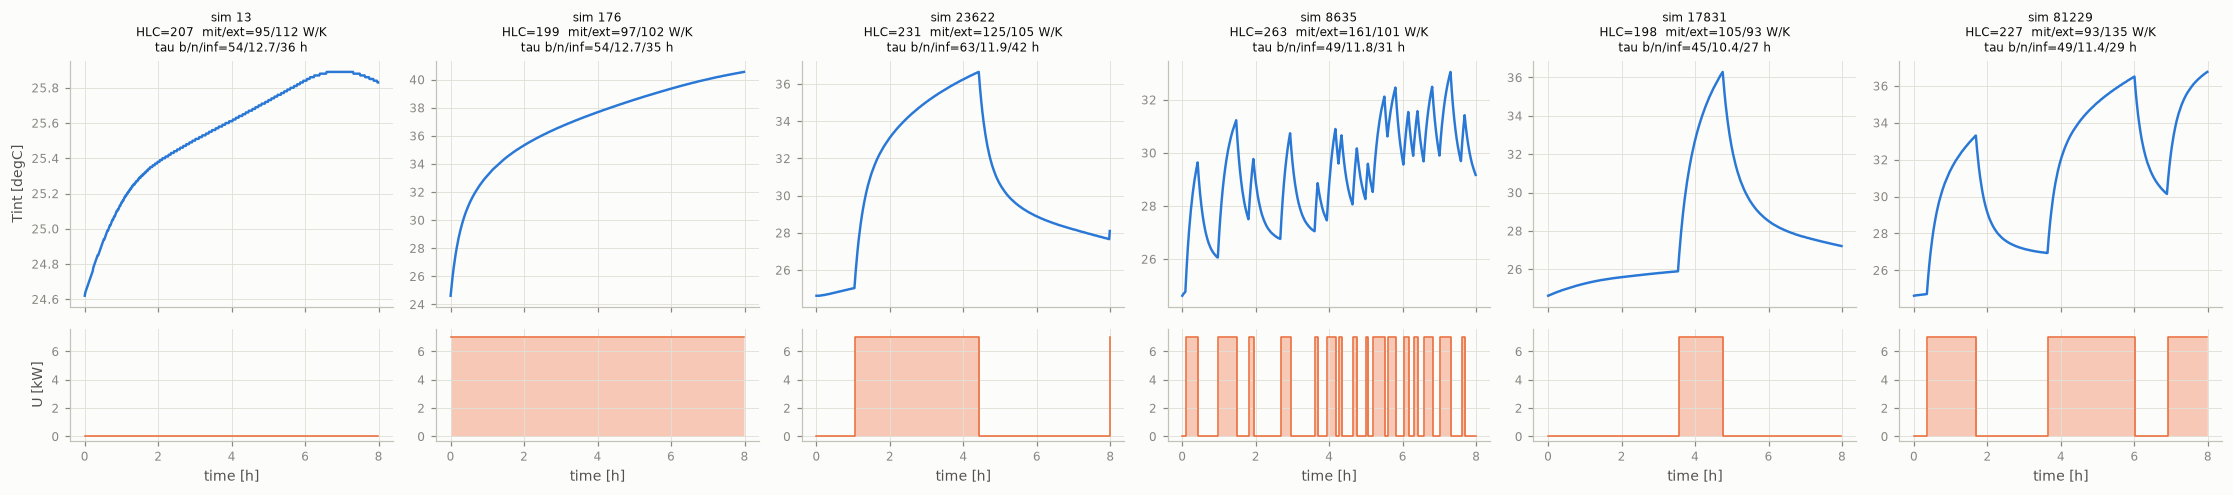

In [16]:
rng = np.random.default_rng(3)
prbs_pool = torch.nonzero((nsw >= 2) & (nsw <= 40)).flatten().numpy()   # readable switching patterns
picks = [int(torch.nonzero(all_off)[0]), int(torch.nonzero(always_on)[0]),
         *rng.choice(prbs_pool, 4, replace=False).tolist()]
fig = P.sample_series(ds.time_hours, T, U, Y, picks)
save(fig, "04_samples")

* With the heater **off**, the air temperature still drifts up by about 1 K in 8 h. The hidden initial
  state (walls warmer than the air) and the boundary conditions (weather, which is not an input) drive a
  **free response** that adds to the heating response. The tiny staircase visible on these flat curves
  is the 0.01 °C rounding.
* When the heater switches **on**, the temperature rises steeply within minutes (only the air and the
  wall surfaces respond), then more slowly. When it switches **off**, the temperature drops quickly and then
  settles. This **fast/slow two-time-scale** shape is the signature of a multi-capacity building.

### 4.2 Ensembles and controlled comparisons

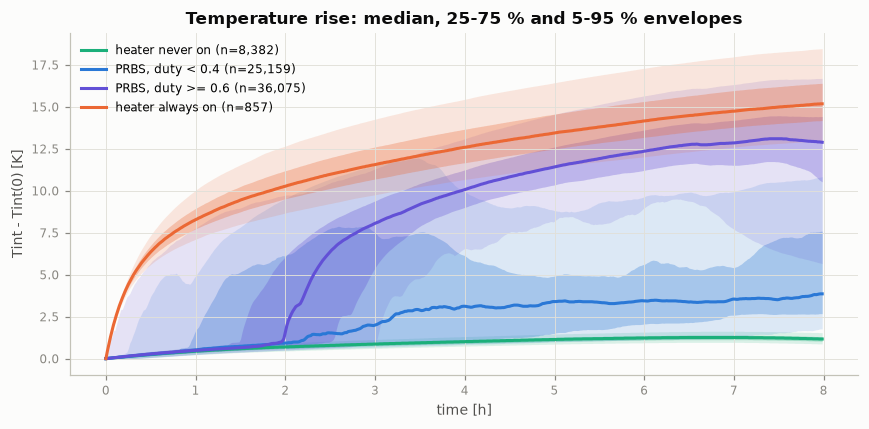

In [17]:
dT = T - T[:, :1]
fig, ax = plt.subplots(figsize=(8, 4))
groups = [("heater never on", all_off, P.SERIES[2]),
          ("PRBS, duty < 0.4", (~all_off) & (~always_on) & (duty < 0.4), P.SERIES[0]),
          ("PRBS, duty >= 0.6", (~always_on) & (duty >= 0.6), P.SERIES[6]),
          ("heater always on", always_on, P.SERIES[1])]
for name, m, c in groups:
    P.quantile_band(ds.time_hours, dT[m], c, f"{name} (n={int(m.sum()):,})", ax)
ax.set_xlabel("time [h]"); ax.set_ylabel("Tint - Tint(0) [K]")
ax.set_title("Temperature rise: median, 25-75 % and 5-95 % envelopes")
ax.legend(loc="upper left"); fig.tight_layout(); save(fig, "04_envelopes")

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
always on,-0.590000,-0.520000,-0.260000,0.020000,-0.290000,-0.100000
never on,-0.180000,-0.190000,-0.030000,-0.190000,-0.230000,-0.210000


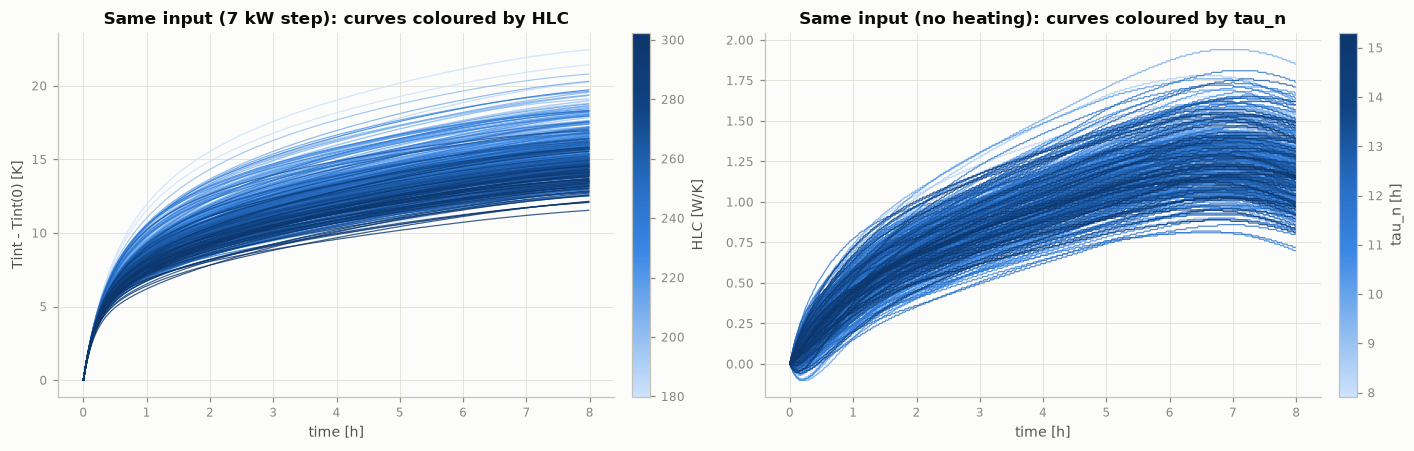

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
P.curves_colored_by(ds.time_hours, dT[always_on], Y[always_on, 0], "HLC",
                    "Same input (7 kW step): curves coloured by HLC", ax=axes[0])
P.curves_colored_by(ds.time_hours, dT[all_off], Y[all_off, 4], "tau_n",
                    "Same input (no heating): curves coloured by tau_n", ax=axes[1])
axes[0].set_ylabel("Tint - Tint(0) [K]")
fig.tight_layout(); save(fig, "04_controlled")

rows = {}
for gname, m in [("always on", always_on), ("never on", all_off)]:
    rows[gname] = {n: np.corrcoef(dT[m, -1].numpy(), Y[m, j].numpy())[0, 1] for j, n in enumerate(TARGET_NAMES)}
pd.DataFrame(rows).T.round(2).style.set_caption("corr( Tint(8h) - Tint(0), target ) within each controlled group")

In [19]:
peak_h = dT[all_off].argmax(1).float() * DT_HOURS
print("free response: time of maximum [h], quantiles 5/25/50/75/95 %:",
      np.quantile(peak_h.numpy(), [0.05, 0.25, 0.5, 0.75, 0.95]).round(2))
spread = pd.Series({"never on (initial state + building)": dT[all_off, -1].std().item(),
                    "always on (building, same 7 kW step)": dT[always_on, -1].std().item()},
                   name="std of Tint(8h) - Tint(0) [K]")
spread.round(2).to_frame()

free response: time of maximum [h], quantiles 5/25/50/75/95 %: [6.02 6.32 6.52 6.72 6.98]


,std of Tint(8h) - Tint(0) [K]
never on (initial state + building),0.21
"always on (building, same 7 kW step)",1.74


**Left panel: always on (constant 7 kW), coloured by HLC. This is the core physical signal.**

* Light curves (low HLC, well insulated) rise **higher** than dark ones (high HLC, leaky). This is the
  steady-state law $\Delta T_\infty = U / HLC$ starting to show.
* With a single step, $\Delta T(t) = P\,g(t)$, where $g(t)$ is the building's step response. $g(t) \to 1/HLC$
  only after several $\tau_b$ (days). At 8 h it is still dominated by the fast part (air, wall surfaces)
  and has only partly picked up the slow part: the curves reach about +15 K out of a final ≈ +30 K.
* The colours therefore **overlap a lot**. The overlap is **not** mainly due to the hidden initial state: in
  the never-on group the initial state moves the 8-hour rise by only ≈ 0.2 K (std above), while under the
  step the spread is ≈ 1.7 K. It comes **mostly from the other building properties** (heat capacities,
  the mit/ext split). HLC is not the only thing that sets an 8-hour rise.

**Right panel: never on, coloured by $\tau_n$.**

* Every curve has the **same shape**: rise, peak, then decline. The peak time is very tight:
  **6.0–7.0 h (5–95 %), median 6.5 h**.
* If the weather differed between simulations, the peaks would be scattered. **A common peak means one common
  driving scenario**, most likely the same forecast day for everyone, as in the paper's off-site phase.
  **Weather is then a constant of the problem, not hidden noise. On the other hand, the model will only
  be valid for that scenario.**
* Colour patterns are weak here. The curves differ mainly because of the **random initial temperatures of
  the wall nodes**, which the paper deliberately randomises (§2.1.2).

**The correlation table** (one number per curve, the 8-hour rise, against each target, within each group):

* Under the step the rise is mainly an **HLC signal** (r ≈ −0.59), mostly through $HLC_{mit}$, the larger and
  more variable part.
* $\tau_b$ has **r ≈ 0** under the step. Its effect at about 50 h is almost invisible in an 8-hour window: a first sign
  that $\tau_b$ will be the hardest target.
* Without heating, the **time constants show up more** (r ≈ −0.2). Nothing masks the slow relaxation of the
  walls, and a slower building (larger τ) drifts less within 8 h.
* This is only one summary number. The full curve (early slope, curvature, response after each switch)
  carries more information, and that is what the model will use.

### 4.3 Dimensionality of the curves

cumulative variance of the first 5 PCs: [0.597 0.791 0.89  0.927 0.951]


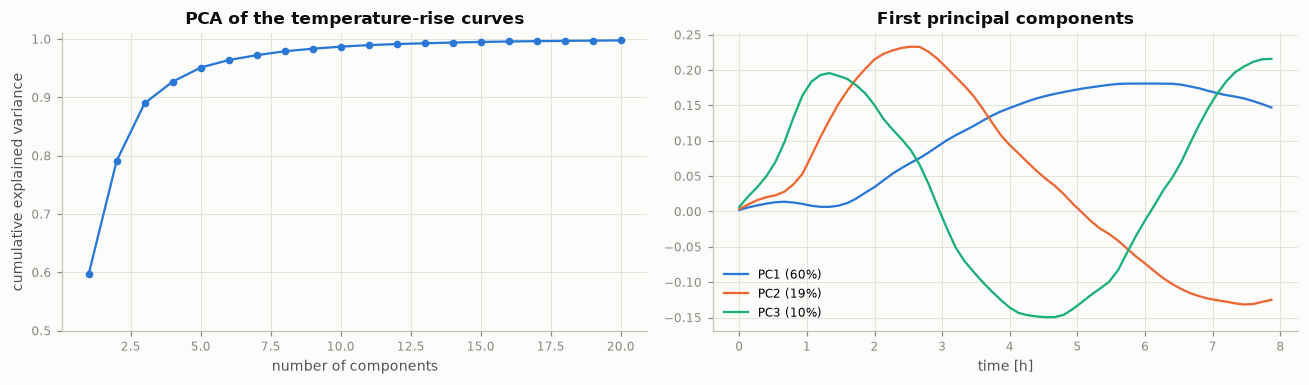

In [20]:
dT_ds = E.downsample(dT, 8)            # 8-minute averages -> 60 points per curve
_, comps, evr = E.pca(dT_ds, 6)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(np.arange(1, 21), evr[:20].cumsum(0).numpy(), marker="o", ms=4, color=P.SERIES[0])
axes[0].set_xlabel("number of components"); axes[0].set_ylabel("cumulative explained variance")
axes[0].set_title("PCA of the temperature-rise curves"); axes[0].set_ylim(0.5, 1.01)
t_ds = np.arange(dT_ds.shape[1]) * 8 / 60
for k in range(3):
    axes[1].plot(t_ds, comps[k].numpy(), color=P.SERIES[k], label=f"PC{k+1} ({evr[k]:.0%})")
axes[1].set_title("First principal components"); axes[1].set_xlabel("time [h]"); axes[1].legend()
fig.tight_layout(); save(fig, "04_pca")
print("cumulative variance of the first 5 PCs:", evr[:5].cumsum(0).numpy().round(3))

**Method.** Every ΔT curve is averaged over 8-minute windows (480 → 60 points; the curves are smooth),
then a PCA finds the few typical shapes whose weighted sums rebuild all curves. This is purely descriptive:
no target is involved.

**How many shapes?** 1 component explains 60 % of the variation between curves, 3 explain 89 %, 5 explain 95 % and
10 explain about 99 %. The 60-point curves live in **about 5–10 dimensions**: they are smooth and highly redundant.

**What the shapes mean.**

* **PC1 (60 %), a slow broad rise:** the overall **amount of heating**, i.e. how high the curve ends up. It
  weighs the second half more, because heat accumulates.
* **PC2 (19 %), positive early (peak ≈ 2.5 h), negative late:** the **timing**, heated early vs. heated late.
* **PC3 (10 %), an early bump, a dip around 4.5 h, then a rise at the end:** a finer timing pattern (on → off → on).

All three describe **how the heater was driven**, not what the building is.

**Why it matters for the model.**

* The heating moves curves by 0–15 K (section 4.2 envelopes), while for a fixed heating the building moves them by
  only ≈ 1.7 K. **The building's signal is a small modulation on top of a curve shaped by $U(t)$.**
* Two curves can therefore look alike just because they were heated alike, even if the buildings differ.
  Looking at $T_{int}$ alone is not enough: the model must read $T_{int}$ **together with $U(t)$**, i.e.
  learn how *this* building responded to *this* heating. This is why $U(t)$ is an input channel.
* The 8-minute averages are fine for this overview, but the minutes right after each switch carry the
  fast-response information. The model should keep the 1-minute series, or at most a mild downsampling.

## 5. Conclusions and implications for modelling

| Finding | Consequence for the model |
|---|---|
| 1M i.i.d. simulations, 480 × 1-min steps, no missing data, identical $T_{int}(0)$ | input $\Delta T = T-T_0$; random or by-batch split is valid |
| all free responses share one shape (peak ≈ 6.5 h) | one fixed weather scenario: learnable implicitly, but the model is scenario-specific |
| $U$ binary 0/7 kW, independent of the building | scale $U/7000$; the model must *condition* on $U$, it cannot shortcut through it |
| $HLC = HLC_{mit}+HLC_{ext}$ exactly | output layer: two softplus heads, HLC = sum (constraint by construction) |
| $\tau_n \le \tau_\infty \le \tau_b$ always; τ block strongly correlated | ordered head ($\tau_\infty=\tau_n+\text{softplus}$, $\tau_b=\tau_\infty+\text{softplus}$), shared trunk |
| right-skewed positive targets, different units | train on standardised **log** targets; report errors per family in physical units and % |
| $HLC_{mit}\perp HLC_{ext}$ | the split must come from the signal; expect it to be the weakest output |
| 8 h is far from steady state (rise still growing; $\tau_b \approx 50$ h) | the model must infer the long-term behaviour from the transient; expect $\tau_b$ to be the hardest output |
| under the same input, the 8 h rise tracks HLC but hardly $\tau_b$ | the building signal is a small modulation of an excitation-driven curve |
| excitation varies widely (never on → always on, slow → fast switching) | stratify the final error analysis by duty cycle and $t_{min}$ (what the paper's excitation design targets) |
| 0.01 °C rounding comparable to per-minute increments | avoid raw finite differences; convolutions over several minutes; consider mild downsampling |

**Next notebook:** the multi-indicator model (CNN-GRU encoder on $(\Delta T, U)$ with the
physics-constrained output layer), evaluated per family of indicators.